In [1]:
cd examples/mitbih

/volatile/home/yb285618/SSF/declearn/examples/mitbih


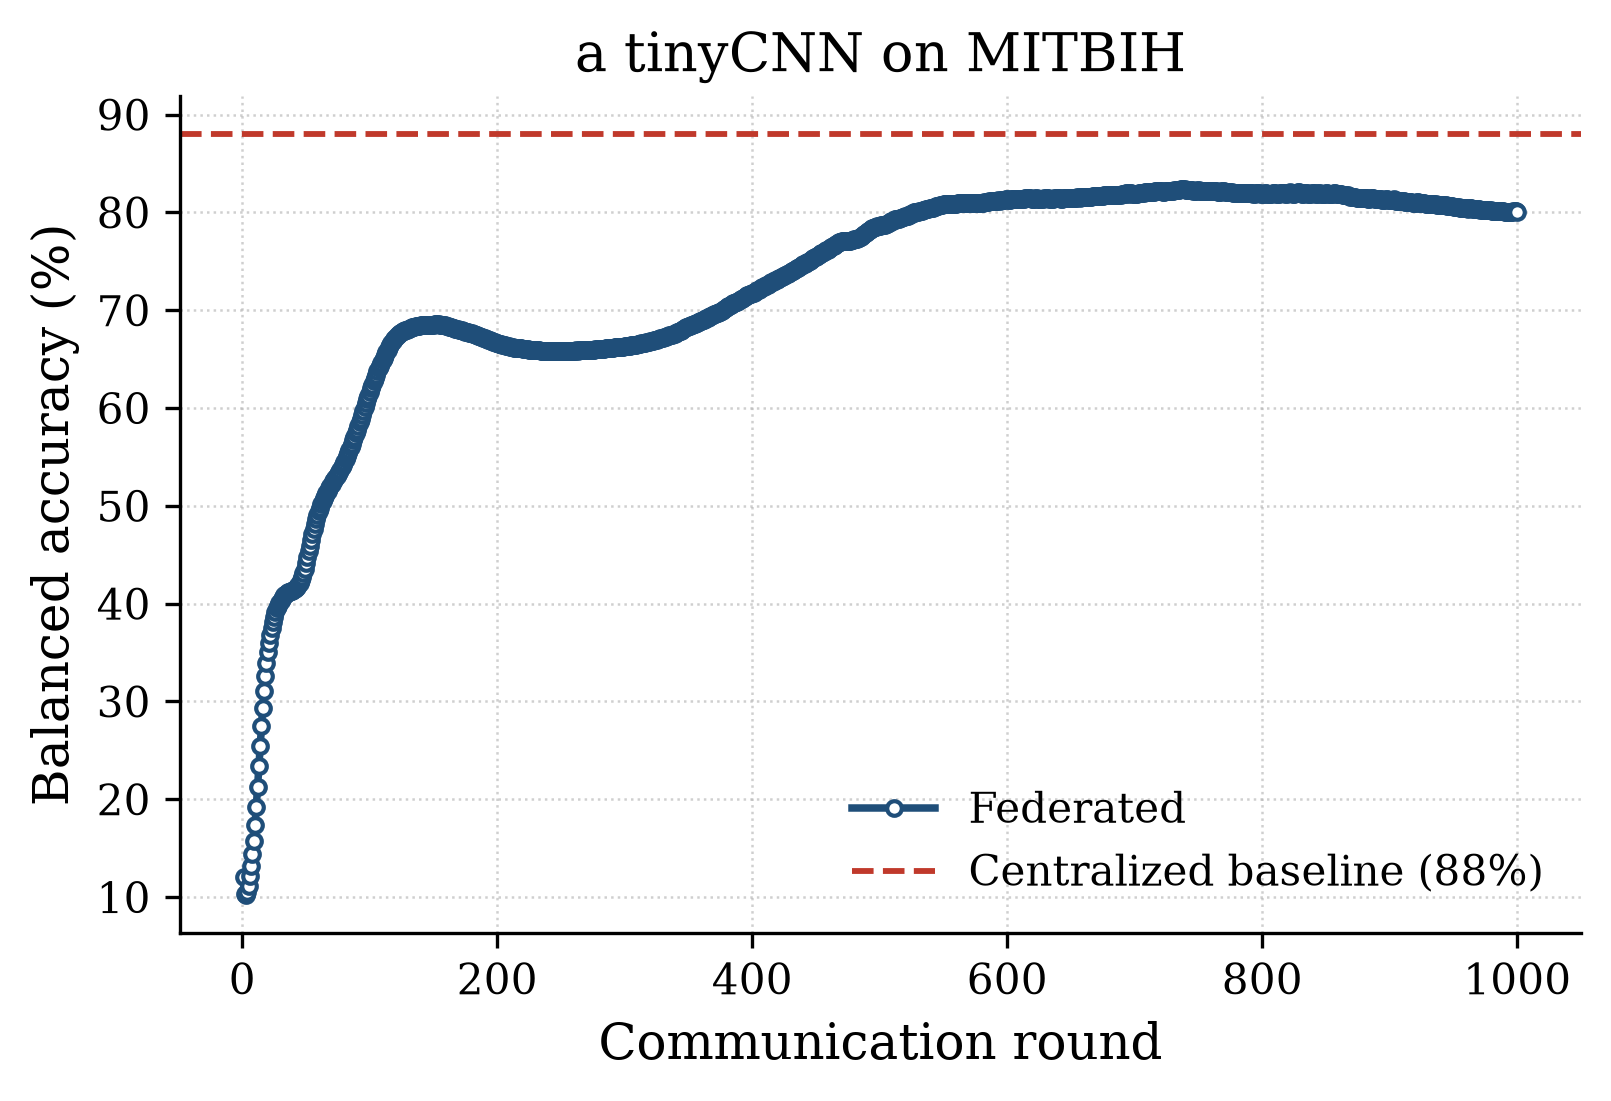

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

# ---- Config ----
CSV_PATH = "result_26-07-08_12-48/server/metrics.csv"
ACC_COL_CANDIDATES = [
    "balanced_accuracy",
    "bal_acc",
    "balanced accuracy",
    "val_balanced_accuracy",
    "test_balanced_accuracy",
    "accuracy",
]
BASELINE = 88.0  # centralized baseline, in % balanced accuracy

# ---- Load data ----
df = pd.read_csv(CSV_PATH)

acc_col = next(
    (c for c in df.columns if c.lower().strip() in ACC_COL_CANDIDATES), None
)
if acc_col is None:
    acc_col = next(
        (
            c
            for c in df.columns
            if any(cand in c.lower() for cand in ACC_COL_CANDIDATES)
        ),
        None,
    )
assert acc_col is not None, (
    f"Could not find a balanced-accuracy column. Columns: {list(df.columns)}"
)

acc = df[acc_col].to_numpy()
if acc.max() <= 1.0:  # normalize 0-1 -> 0-100
    acc = acc * 100.0

rounds = range(1, len(df) + 1)  # each row is one round

# ---- Paper-quality styling ----
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 11,
        "axes.labelsize": 12,
        "axes.titlesize": 13,
        "legend.fontsize": 10,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "axes.linewidth": 0.8,
        "figure.dpi": 300,
        "savefig.dpi": 300,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

fig, ax = plt.subplots(figsize=(5.5, 3.8))

ax.plot(
    rounds,
    acc,
    color="#1f4e79",
    linewidth=1.8,
    marker="o",
    markersize=3.5,
    markerfacecolor="white",
    markeredgewidth=1.0,
    label="Federated",
)

ax.axhline(
    BASELINE,
    color="#c0392b",
    linewidth=1.4,
    linestyle="--",
    label=f"Centralized baseline ({BASELINE:g}%)",
)

ax.set_xlabel("Communication round")
ax.set_ylabel("Balanced accuracy (%)")
ax.set_title("a tinyCNN on MITBIH")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(True, linestyle=":", linewidth=0.6, alpha=0.6)

ax.legend(frameon=False, loc="lower right")

fig.tight_layout()
fig.savefig("balanced_accuracy.pdf", bbox_inches="tight")
plt.show()